In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
print("GPU Details:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.18.0
Num GPUs Available: 0
GPU Details: []


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers


In [4]:
# Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize and reshape data
x_train = x_train.reshape(-1, 28*28).astype("float32") / 255.0
x_test = x_test.reshape(-1, 28*28).astype("float32") / 255.0

# Define the model
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(784,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 classes for digits 0–9
])

# Display model architecture
model.summary()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [6]:
history = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=32
)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8610 - loss: 0.4812 - val_accuracy: 0.9560 - val_loss: 0.1462
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9640 - loss: 0.1201 - val_accuracy: 0.9683 - val_loss: 0.1112
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9744 - loss: 0.0787 - val_accuracy: 0.9678 - val_loss: 0.1052
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9823 - loss: 0.0571 - val_accuracy: 0.9739 - val_loss: 0.0922
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9870 - loss: 0.0409 - val_accuracy: 0.9740 - val_loss: 0.0936


In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9700 - loss: 0.1015

Test Loss: 0.0864
Test Accuracy: 0.9742


In [8]:
# Predict first 5 samples
predictions = model.predict(x_test[:5])

# Display predictions
for i, pred in enumerate(predictions):
    print(f"Sample {i+1} - Predicted Label: {np.argmax(pred)} | True Label: {y_test[i]}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Sample 1 - Predicted Label: 7 | True Label: 7
Sample 2 - Predicted Label: 2 | True Label: 2
Sample 3 - Predicted Label: 1 | True Label: 1
Sample 4 - Predicted Label: 0 | True Label: 0
Sample 5 - Predicted Label: 4 | True Label: 4


Saving are-my-number-handwrittings-that-bad-v0-461moihpnnje1.webp to are-my-number-handwrittings-that-bad-v0-461moihpnnje1.webp


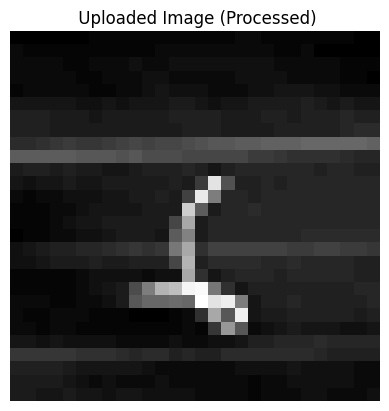

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
 Predicted Digit: 8
 Confidence Scores: [[0.001 0.    0.176 0.009 0.    0.194 0.056 0.    0.563 0.   ]]


In [11]:
from google.colab import files
from PIL import Image, ImageOps

# Upload image
uploaded = files.upload()

# Pick uploaded filename
for filename in uploaded.keys():
    user_img = Image.open(filename).convert("L")  # Convert to grayscale
    user_img = ImageOps.invert(user_img)          # Invert colors (white on black)
    user_img = user_img.resize((28, 28))          # Resize to 28x28

    # Display uploaded image
    plt.imshow(user_img, cmap='gray')
    plt.title(" Uploaded Image (Processed)")
    plt.axis('off')
    plt.show()

    # Convert to numpy and normalize
    img_array = np.array(user_img).reshape(1, 784).astype("float32") / 255.0

    # Predict
    pred = model.predict(img_array)
    predicted_label = np.argmax(pred)

    print(f" Predicted Digit: {predicted_label}")
    print(f" Confidence Scores: {np.round(pred, 3)}")
